# Titanic CSV Data Analysis with NumPy and Matplotlib

This notebook uses `DA/test.csv` as a real tabular dataset. It demonstrates a careful workflow: inspect the file, check missing values, calculate numerical summaries, and select graphs that fit the columns. It also connects this work to a simulated IoT sensor pipeline.

The CSV contains passenger records from a Titanic test dataset. It has no `Survived` column, so it cannot be used to calculate or infer survival outcomes. The analysis here describes the records in this file only.

Required libraries: `pandas`, `numpy`, and `matplotlib`. Install them in the Jupyter environment if needed with `pip install pandas numpy matplotlib`.


## 1. Load the data and inspect its structure

Pandas reads the CSV into a DataFrame, a labeled table with rows and columns. The first checks show a few rows, the number of rows and columns, the column names, and the inferred data types. Inspecting first helps ensure that later calculations use the intended fields.


In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display

candidates = [Path("test.csv"), Path("DA") / "test.csv"]
DATA_PATH = next((path for path in candidates if path.exists()), candidates[0])
if not DATA_PATH.exists():
    raise FileNotFoundError("Place test.csv beside this notebook or in the DA folder.")

df = pd.read_csv(DATA_PATH)
print("Using:", DATA_PATH.resolve())
display(df.head())
print("Rows and columns:", df.shape)
print("Column names:", df.columns.tolist())
print("Data types:")
print(df.dtypes)


Using: C:\Users\ashir\OneDrive\Desktop\Mirai\AKTU\Python\Python_fundas\DA\test.csv


,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


Rows and columns: (418, 11)
Column names: ['PassengerId', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']
Data types:
PassengerId      int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object


The supplied file has 418 rows and 11 columns. Its fields include ticket class (`Pclass`), recorded sex category (`Sex`), age (`Age`), family counts (`SibSp`, `Parch`), fare (`Fare`), cabin (`Cabin`), and embarkation port (`Embarked`). The `PassengerId` and ticket fields identify records; they are not numerical measurements to average.


## 2. Check missing values

A missing value means that a field has no recorded value for that row. Count missing values before deciding how to analyze a column. Dropping missing values is appropriate for calculations that require numbers, but filling them with an estimate changes the data and needs a clear reason.


In [2]:
missing_counts = df.isna().sum()
print("Missing values by column:")
print(missing_counts)
print("\nMissing values in selected fields:")
display(df[["Age", "Fare", "Cabin"]].isna().sum().to_frame("missing_count"))


Missing values by column:
PassengerId      0
Pclass           0
Name             0
Sex              0
Age             86
SibSp            0
Parch            0
Ticket           0
Fare             1
Cabin          327
Embarked         0
dtype: int64

Missing values in selected fields:


,missing_count
Age,86
Fare,1
Cabin,327


In this dataset, many `Cabin` entries are missing, some `Age` values are missing, and one `Fare` value is missing. For age calculations, `dropna()` keeps only records with a known age. A median-filled age can be useful in some analyses, but it is an imputed value, not an observed age. The next cell shows the operation separately so that the choice is explicit.


In [3]:
known_ages = df["Age"].dropna()
print("Known ages:", len(known_ages))
print("Missing ages:", df["Age"].isna().sum())

# Optional example: create a separate column with missing ages filled by the median.
df["Age_filled_with_median"] = df["Age"].fillna(df["Age"].median())
print("Median used for filling:", df["Age"].median())


Known ages: 332
Missing ages: 86
Median used for filling: 27.0


## 3. Numerical summaries with NumPy

`dropna()` removes missing values from the selected numerical column. `to_numpy()` converts the remaining values to a NumPy array. NumPy can then calculate the mean, minimum, maximum, range, median, and standard deviation. The standard deviation describes the spread around the mean; here the default is the population standard deviation (`ddof=0`).


In [4]:
import numpy as np

ages = df["Age"].dropna().to_numpy()
fares = df["Fare"].dropna().to_numpy()

print(f"Known ages: {ages.size}")
print(f"Mean age: {np.mean(ages):.2f} years")
print(f"Youngest age: {np.min(ages):.2f} years")
print(f"Oldest age: {np.max(ages):.2f} years")
print(f"Median age: {np.median(ages):.2f} years")
print(f"Age standard deviation: {np.std(ages):.2f} years")
print(f"Mean fare: {np.mean(fares):.2f}")
print(f"Fare range: {np.max(fares) - np.min(fares):.2f}")


Known ages: 332
Mean age: 30.27 years
Youngest age: 0.17 years
Oldest age: 76.00 years
Median age: 27.00 years
Age standard deviation: 14.16 years
Mean fare: 35.63
Fare range: 512.33


These summaries describe passengers with recorded values in the selected columns. They do not explain why values differ, and the mean can be affected by unusually large fares. Keep units with measurements and state which missing records were excluded.


## 4. Bar chart: records by ticket class

A bar chart compares counts across categories. `value_counts()` counts the records in each class; sorting by index keeps classes in numerical order. The bars show how many rows in this file belong to each ticket class, not the number of people who survived.


Pclass
1    107
2     93
3    218
Name: count, dtype: int64


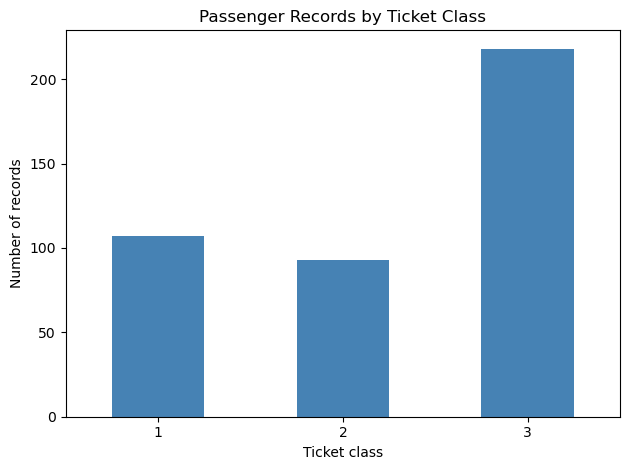

In [5]:
import matplotlib.pyplot as plt

class_counts = df["Pclass"].value_counts().sort_index()
print(class_counts)

class_counts.plot(kind="bar", color="steelblue")
plt.title("Passenger Records by Ticket Class")
plt.xlabel("Ticket class")
plt.ylabel("Number of records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


Class 3 has the largest count in this dataset. This is a count comparison; the chart contains no outcome information.


## 5. Histogram: age distribution

A histogram groups numerical measurements into intervals called bins. The height of a bar indicates how many known ages fall within that interval. The chart excludes missing ages, so it represents only records with an age value. Changing the number of bins changes the detail shown.


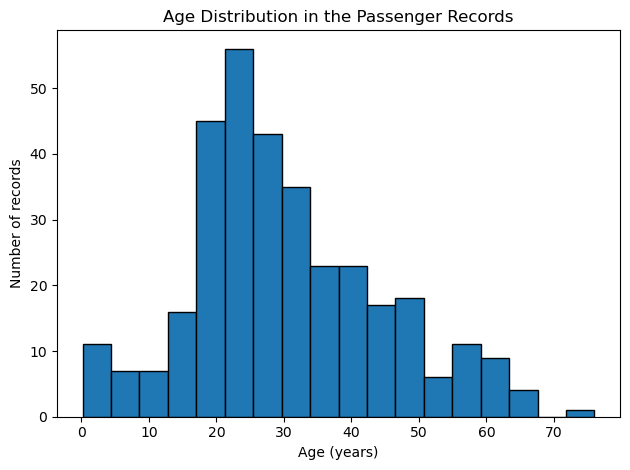

Records included: 332


In [6]:
plt.hist(known_ages, bins=18, edgecolor="black")
plt.title("Age Distribution in the Passenger Records")
plt.xlabel("Age (years)")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()
print("Records included:", len(known_ages))


## 6. Box plot: fares by ticket class

A box plot compares the center and spread of numerical values across groups. Here, the groups are ticket classes. Missing fares are excluded from their class group. The plot is descriptive and does not explain why fares differ.


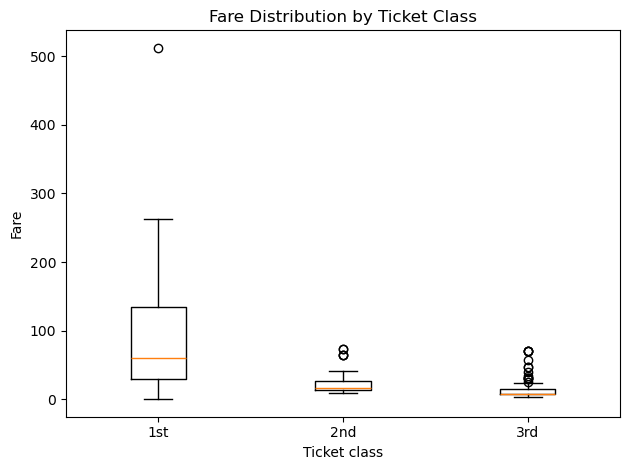

Records with known fare per class: [107, 93, 217]


In [7]:
fare_groups = [
    df.loc[df["Pclass"] == ticket_class, "Fare"].dropna().to_numpy()
    for ticket_class in [1, 2, 3]
]

plt.boxplot(fare_groups)
plt.title("Fare Distribution by Ticket Class")
plt.xlabel("Ticket class")
plt.ylabel("Fare")
plt.xticks([1, 2, 3], ["1st", "2nd", "3rd"])
plt.tight_layout()
plt.show()
print("Records with known fare per class:", [len(group) for group in fare_groups])


The box plot makes differences in fare distributions visible, including the median and spread. Individual high or low values may extend beyond the box. Avoid turning an observed association into a claim about its cause.


## 7. Bar chart: records by recorded sex category

`value_counts()` also summarizes categories such as the recorded `Sex` field. The chart below shows counts in this file. These labels describe the dataset's recorded categories and should not be confused with a survival comparison.


Sex
male      266
female    152
Name: count, dtype: int64


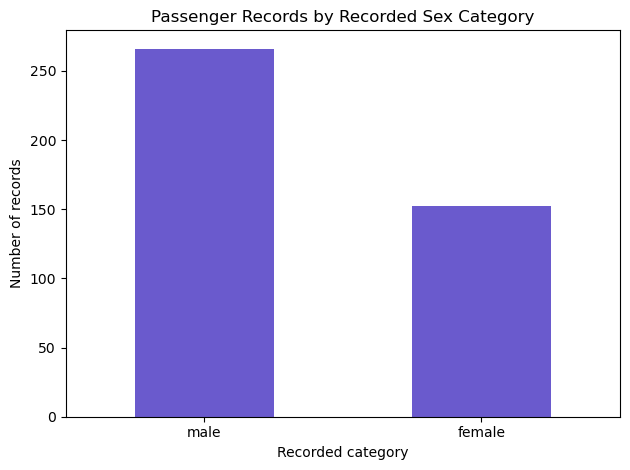

In [8]:
sex_counts = df["Sex"].value_counts()
print(sex_counts)
sex_counts.plot(kind="bar", color="slateblue")
plt.title("Passenger Records by Recorded Sex Category")
plt.xlabel("Recorded category")
plt.ylabel("Number of records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 8. NumPy and Matplotlib together

NumPy calculates summaries; Matplotlib displays the distribution. A vertical line marks the mean age on the histogram. The mean is a useful reference, while the shape of the histogram shows whether values cluster or spread across age ranges.


Mean age: 30.27 years
Median age: 27.00 years
Standard deviation: 14.16 years


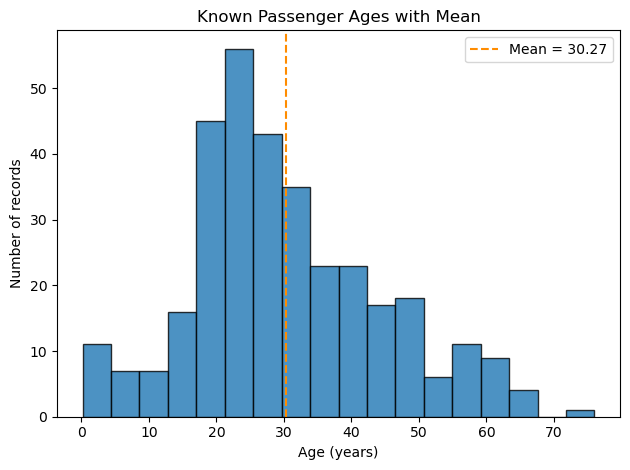

In [9]:
mean_age = float(np.mean(ages))
print(f"Mean age: {mean_age:.2f} years")
print(f"Median age: {np.median(ages):.2f} years")
print(f"Standard deviation: {np.std(ages):.2f} years")

plt.hist(ages, bins=18, edgecolor="black", alpha=0.8)
plt.axvline(mean_age, color="darkorange", linestyle="--", label=f"Mean = {mean_age:.2f}")
plt.title("Known Passenger Ages with Mean")
plt.xlabel("Age (years)")
plt.ylabel("Number of records")
plt.legend()
plt.tight_layout()
plt.show()


## 9. What this file can and cannot show

The file can support descriptive summaries of its recorded class, age, fare, sex category, and other available fields. It cannot answer who survived or calculate survival rates because it has no `Survived` column. Charts should be chosen to match the data: bars compare categories, histograms show a numerical distribution, box plots compare numerical distributions across groups, and line graphs show values in an ordered sequence such as time.


## 10. Connection to IoT sensor analysis

The same workflow applies to sensor data. A passenger CSV is a stored snapshot; a sensor CSV might contain a time and temperature for each measurement. Both can be read, checked, summarized, and plotted. The source and meaning of the data differ, but the tools and general pipeline are similar.

The following program simulates readings, writes them to a CSV file, reads the file back, calculates a NumPy mean, and plots the ordered values. No physical sensor is connected.


In [10]:
import csv
from pathlib import Path

simulated_readings = [
    ("09:00", 24.5),
    ("10:00", 25.2),
    ("11:00", 26.1),
    ("12:00", 27.4),
    ("13:00", 27.0),
]
sensor_path = Path("sensor_readings.csv")
with sensor_path.open("w", newline="", encoding="utf-8") as file:
    writer = csv.writer(file)
    writer.writerow(["time", "temperature_c"])
    writer.writerows(simulated_readings)
print(f"Saved simulated readings to {sensor_path.resolve()}")


Saved simulated readings to C:\Users\ashir\OneDrive\Desktop\Mirai\AKTU\Python\Python_fundas\DA\sensor_readings.csv


Mean temperature: 26.04 °C


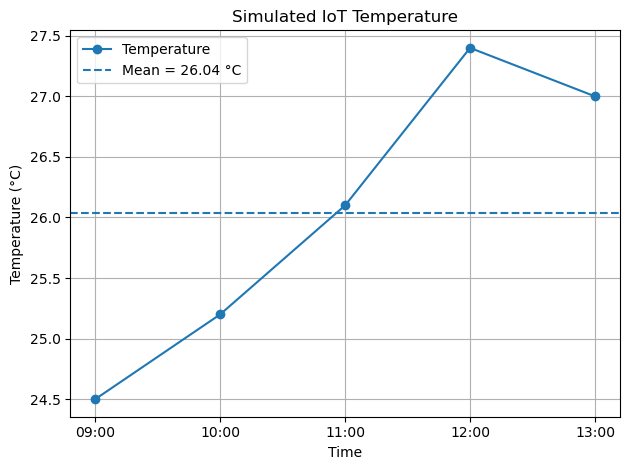

In [11]:
sensor_times = []
sensor_temps = []
with sensor_path.open("r", newline="", encoding="utf-8") as file:
    for row in csv.DictReader(file):
        sensor_times.append(row["time"])
        sensor_temps.append(float(row["temperature_c"]))

sensor_values = np.array(sensor_temps)
sensor_mean = float(np.mean(sensor_values))
print(f"Mean temperature: {sensor_mean:.2f} °C")

plt.plot(sensor_times, sensor_values, marker="o", label="Temperature")
plt.axhline(sensor_mean, linestyle="--", label=f"Mean = {sensor_mean:.2f} °C")
plt.title("Simulated IoT Temperature")
plt.xlabel("Time")
plt.ylabel("Temperature (°C)")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


The example shows the shared process: collect or receive records, save them, read and clean the file, calculate summaries, choose a suitable graph, and describe the result. A live sensor system may repeat this process as new measurements arrive.


## Summary

Inspect a dataset before analyzing it. Check column names, shapes, types, and missing values. Remove missing entries only where the calculation requires them, and explain the choice. NumPy handles numerical summaries; Matplotlib visualizes patterns; pandas makes tabular inspection and grouping convenient. This Titanic test file supports descriptive analysis, but no survival conclusions. The IoT example uses the same workflow with simulated time-series readings.
